In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
# Cell 1: check the GPU
import torch  # PyTorch is the deep-learning library Stable-Baselines3 is built on

print("PyTorch version:", torch.__version__)
print("GPU available  :", torch.cuda.is_available())  # True means training will use the GPU
if torch.cuda.is_available():
    print("GPU name       :", torch.cuda.get_device_name(0))
else:
    print("No GPU found! Turn on a GPU accelerator in the notebook settings, then run this cell again.")

PyTorch version: 2.11.0+cu128
GPU available  : True
GPU name       : Tesla T4


In [2]:
# Cell 2: install everything (takes about 1 minute)
!pip install -q "stable-baselines3[extra]" "gymnasium[atari]" ale-py imageio imageio-ffmpeg

In [3]:
# Cell 3: imports
import os
import glob
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import gymnasium as gym
import ale_py                      # the Atari emulator
import stable_baselines3 as sb3
from stable_baselines3 import DQN
from stable_baselines3.common.env_util import make_atari_env           # builds a ready-to-train Atari env
from stable_baselines3.common.vec_env import VecFrameStack             # stacks several frames together
from stable_baselines3.common.evaluation import evaluate_policy        # measures how good the agent is
from stable_baselines3.common.callbacks import CheckpointCallback      # saves the model during training

gym.register_envs(ale_py)  # tell Gymnasium about the Atari games

print("gymnasium        :", gym.__version__)
print("ale-py           :", ale_py.__version__)
print("stable-baselines3:", sb3.__version__)

gymnasium        : 1.2.0
ale-py           : 0.12.1
stable-baselines3: 2.9.2


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


In [4]:
# Cell 4: configuration
ENV_ID = "BreakoutNoFrameskip-v4"   # which game to play
TOTAL_TIMESTEPS = 5_000_000         # how long to train (agent steps)
MAX_TRAIN_MINUTES = 420             # safety stop after 7 hours so the run never hits Kaggle's session cap
SEED = 42                           # makes runs more repeatable

# Use Kaggle's output folder if we're on Kaggle, otherwise Colab's /content
BASE_DIR = "/kaggle/working" if os.path.exists("/kaggle/working") else "/content"
MODEL_DIR = f"{BASE_DIR}/models"    # saved models go here
LOG_DIR = f"{BASE_DIR}/logs"        # training scores are logged here
VIDEO_DIR = f"{BASE_DIR}/videos"    # the gameplay video goes here
for folder in (MODEL_DIR, LOG_DIR, VIDEO_DIR):
    os.makedirs(folder, exist_ok=True)  # create the folders if they don't exist yet

A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]


Observation space: Box(0, 255, (210, 160, 3), uint8)
Action space     : Discrete(4)
Action meanings  : ['NOOP', 'FIRE', 'RIGHT', 'LEFT']


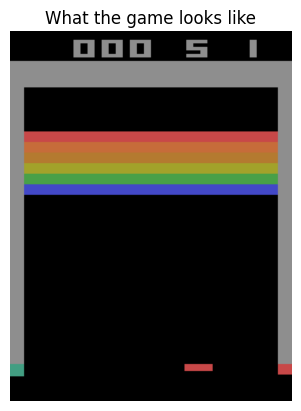

In [5]:
# Cell 5: peek at the raw environment
raw_env = gym.make(ENV_ID)
print("Observation space:", raw_env.observation_space)  # a 210x160 colour image
print("Action space     :", raw_env.action_space)       # 4 discrete actions
print("Action meanings  :", raw_env.unwrapped.get_action_meanings())

obs, info = raw_env.reset(seed=SEED)  # start a new game and get the first screen
plt.imshow(obs)
plt.axis("off")
plt.title("What the game looks like")
plt.show()
raw_env.close()

In [6]:
# Cell 6: training environment
train_env = make_atari_env(
    ENV_ID,
    n_envs=1,              # one game at a time (simple and what DQN usually uses)
    seed=SEED,
    monitor_dir=LOG_DIR,   # saves the real score of every finished game to a CSV file
)
train_env = VecFrameStack(train_env, n_stack=4)  # the agent sees the last 4 frames together

print("Observation space the agent sees:", train_env.observation_space)  # (84, 84, 4)
print("Number of actions               :", train_env.action_space.n)

Observation space the agent sees: Box(0, 255, (84, 84, 4), uint8)
Number of actions               : 4


In [7]:
# Cell 7: create the DQN model
model = DQN(
    "CnnPolicy",                  # convolutional network, made for image inputs
    train_env,
    learning_rate=1e-4,           # how big each learning step is
    buffer_size=100_000,          # how many past steps the replay buffer remembers
    learning_starts=100_000,      # collect this much experience before learning begins
    batch_size=32,                # how many remembered steps to learn from at once
    gamma=0.99,                   # how much future rewards matter (close to 1 = far-sighted)
    train_freq=4,                 # do one learning update every 4 game steps
    gradient_steps=1,             # number of updates each time
    target_update_interval=1_000, # how often to refresh the stable "target" network
    exploration_fraction=0.1,     # exploration shrinks over the first 10% of training
    exploration_initial_eps=1.0,  # at first, 100% random actions
    exploration_final_eps=0.01,   # later, only 1% random actions
    optimize_memory_usage=True,   # saves RAM in the replay buffer
    replay_buffer_kwargs={"handle_timeout_termination": False},  # required when optimize_memory_usage=True
    verbose=1,                    # print training progress
    seed=SEED,
    device="auto",                # uses the GPU if there is one
)
print(model.policy)  # shows the neural network layers

Using cuda device
Wrapping the env in a VecTransposeImage.
CnnPolicy(
  (q_net): QNetwork(
    (features_extractor): NatureCNN(
      (cnn): Sequential(
        (0): Conv2d(4, 32, kernel_size=(8, 8), stride=(4, 4))
        (1): ReLU()
        (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2))
        (3): ReLU()
        (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
        (5): ReLU()
        (6): Flatten(start_dim=1, end_dim=-1)
      )
      (linear): Sequential(
        (0): Linear(in_features=3136, out_features=512, bias=True)
        (1): ReLU()
      )
    )
    (q_net): Sequential(
      (0): Linear(in_features=512, out_features=4, bias=True)
    )
  )
  (q_net_target): QNetwork(
    (features_extractor): NatureCNN(
      (cnn): Sequential(
        (0): Conv2d(4, 32, kernel_size=(8, 8), stride=(4, 4))
        (1): ReLU()
        (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2))
        (3): ReLU()
        (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
 

In [8]:
# Cell 8: train
from stable_baselines3.common.callbacks import BaseCallback

class TimeLimitCallback(BaseCallback):
    # Stops training cleanly after max_minutes, so the cells after this one still run and save results
    def __init__(self, max_minutes):
        super().__init__()
        self.max_seconds = max_minutes * 60
        self.t0 = None

    def _on_training_start(self):
        self.t0 = time.time()                         # remember when training began

    def _on_step(self) -> bool:
        return (time.time() - self.t0) < self.max_seconds   # returning False stops training

checkpoint_cb = CheckpointCallback(
    save_freq=250_000,                 # save every 250k steps
    save_path=MODEL_DIR,
    name_prefix="dqn_breakout_ckpt",
)

start = time.time()
model.learn(
    total_timesteps=TOTAL_TIMESTEPS,
    callback=[checkpoint_cb, TimeLimitCallback(MAX_TRAIN_MINUTES)],
    log_interval=100,                  # print a stats table every 100 episodes (less spam)
    progress_bar=False,                # progress bars make messy logs in background runs
)
print(f"Training finished in {(time.time() - start) / 60:.1f} minutes ({model.num_timesteps} steps)")

----------------------------------
| rollout/            |          |
|    ep_len_mean      | 700      |
|    ep_rew_mean      | 1.05     |
|    exploration_rate | 0.994    |
| time/               |          |
|    episodes         | 100      |
|    fps              | 562      |
|    time_elapsed     | 5        |
|    total_timesteps  | 3159     |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 715      |
|    ep_rew_mean      | 1.12     |
|    exploration_rate | 0.987    |
| time/               |          |
|    episodes         | 200      |
|    fps              | 576      |
|    time_elapsed     | 11       |
|    total_timesteps  | 6476     |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 708      |
|    ep_rew_mean      | 1.12     |
|    exploration_rate | 0.981    |
| time/               |          |
|    episodes       

In [9]:
# Cell 9: save the final model
final_model_path = f"{MODEL_DIR}/dqn_breakout_final"
model.save(final_model_path)  # creates dqn_breakout_final.zip
print("Saved to", final_model_path + ".zip")

Saved to /kaggle/working/models/dqn_breakout_final.zip


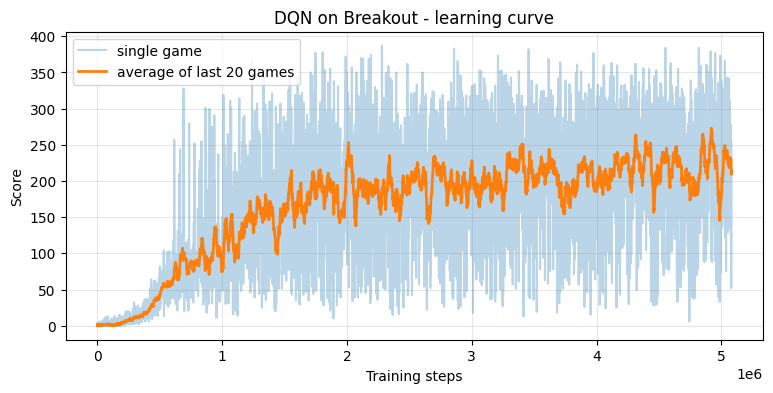

In [10]:
# Cell 11: learning curve
log_file = glob.glob(f"{LOG_DIR}/*.monitor.csv")[0]
df = pd.read_csv(log_file, skiprows=1)  # the first line is a header comment, so skip it

# 'r' = score of the game, 'l' = game length in raw frames.
# The agent repeats each action 4 times, so dividing by 4 gives agent steps.
df["steps"] = df["l"].cumsum() / 4
df["smooth"] = df["r"].rolling(window=20, min_periods=1).mean()  # average of the last 20 games

plt.figure(figsize=(9, 4))
plt.plot(df["steps"], df["r"], alpha=0.3, label="single game")
plt.plot(df["steps"], df["smooth"], linewidth=2, label="average of last 20 games")
plt.xlabel("Training steps")
plt.ylabel("Score")
plt.title("DQN on Breakout - learning curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [11]:
# Cell 12: evaluation
eval_env = make_atari_env(
    ENV_ID,
    n_envs=1,
    seed=SEED + 1,  # a different seed from training
    wrapper_kwargs={"terminal_on_life_loss": False, "clip_reward": False},  # real scores, full games
)
eval_env = VecFrameStack(eval_env, n_stack=4)

model.exploration_rate = 0.05  # small amount of randomness during evaluation
mean_reward, std_reward = evaluate_policy(
    model,
    eval_env,
    n_eval_episodes=10,    # play 10 full games
    deterministic=False,   # allows the 5% random actions set above
)
print(f"Average score over 10 games: {mean_reward:.1f} +/- {std_reward:.1f}")
print("For comparison, a random player scores about 1-2.")
eval_env.close()

Average score over 10 games: 194.0 +/- 66.6
For comparison, a random player scores about 1-2.


In [12]:
# Cell 13: record one game to a video file
import imageio

video_env = make_atari_env(
    ENV_ID,
    n_envs=1,
    seed=123,
    wrapper_kwargs={"terminal_on_life_loss": False, "clip_reward": False},
    env_kwargs={"render_mode": "rgb_array"},  # lets us read the screen as an image
)
video_env = VecFrameStack(video_env, n_stack=4)

MAX_STEPS = 5000                # safety limit so a stuck agent can't record forever
model.exploration_rate = 0.05   # same small randomness as in evaluation

obs = video_env.reset()
frames = [video_env.render()]   # first screen
game_score = 0.0

for step in range(MAX_STEPS):
    action, _ = model.predict(obs, deterministic=False)   # the agent chooses an action
    obs, reward, done, info = video_env.step(action)       # the game advances 4 frames
    frames.append(video_env.render())                      # save the screen image
    game_score += float(reward[0])                         # real (unclipped) score
    if done[0]:                                            # game over -> stop recording
        break

video_env.close()

video_path = f"{VIDEO_DIR}/breakout_dqn.mp4"
imageio.mimsave(video_path, frames, fps=30, macro_block_size=1)  # write the .mp4
print(f"Recorded {len(frames)} frames, game score = {game_score:.0f}")
print("Saved video to", video_path)

Recorded 2250 frames, game score = 222
Saved video to /kaggle/working/videos/breakout_dqn.mp4


In [13]:
# Cell 14: show the video in the notebook
from base64 import b64encode
from IPython.display import HTML

with open(video_path, "rb") as f:
    video_b64 = b64encode(f.read()).decode()  # embed the video directly in the page

HTML(f'<video width="480" controls><source src="data:video/mp4;base64,{video_b64}" type="video/mp4"></video>')

In [14]:
# Cell 15 (Kaggle): create download links for the video and model
from IPython.display import FileLink, display

display(FileLink(video_path))                  # gameplay video
display(FileLink(final_model_path + ".zip"))   # trained agent

/kaggle/working/videos/breakout_dqn.mp4

/kaggle/working/models/dqn_breakout_final.zip